In [38]:
%matplotlib inline

import os
import numpy as np
import scipy as sp
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from dateutil.tz import tzutc
from dateutil.parser import parse
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from datetime import datetime, timezone
from py_wave_runup import models


## 1. Load Data Files


In [39]:

SS_PATH = "C:\\Users\\cvolp\\shorescan_processing\\output_plots\\Dec_2024_noTWLrecompute\\processed\\Shorescan_TWL_viewer_Dec_2024_noTWLrecompute_20241201-20241231.csv"
PUV_PATH = "..\\..\\shorescan_processing\\DATA\\sig1000_waves_ALL.csv"

# Load Shorescan Output
df_ss=pd.read_csv(SS_PATH)
df_ss.index=pd.to_datetime(df_ss.pop('dt0'),utc=True)
df_ss_c1 = df_ss[df_ss['camera']=='c1']
df_ss_c2 = df_ss[df_ss['camera']=='c2']
df_ss_c1 = df_ss_c1.drop(columns=['camera','timestamp','dt0_utc','t_mid_utc','filename','station','use','clipped','implausible','excluded','twl_source','n_samples','n_valid','n_at_limit','n_zero'])
df_ss_c2 = df_ss_c2.drop(columns=['camera','timestamp','dt0_utc','t_mid_utc','filename','station','use','clipped','implausible','excluded','twl_source','n_samples','n_valid','n_at_limit','n_zero'])
df_ss_c1 = df_ss_c1.apply(pd.to_numeric, errors="coerce")
df_ss_c2 = df_ss_c2.apply(pd.to_numeric, errors="coerce")
df_ss_c1.index.name = "datetime"
df_ss_c2.index.name = "datetime"

dfs_ss_c1 = {}
for val, group in df_ss_c1.groupby("transect"):
    g = group.sort_index(kind="stable")            # stable: ties keep file order
    dfs_ss_c1[val] = g[~g.index.duplicated(keep="first")]

dfs_ss_c2 = {}
for val, group in df_ss_c2.groupby("transect"):
    g = group.sort_index(kind="stable")            # stable: ties keep file order
    dfs_ss_c2[val] = g[~g.index.duplicated(keep="first")]

print(f"Transects found: {list(dfs_ss_c1.keys())}")
print(f"Transects found: {list(dfs_ss_c2.keys())}")

transects = list(dfs_ss_c1.keys())

df_ss20_c1 = dfs_ss_c1[transects[0]]
df_ss30_c1 = dfs_ss_c1[transects[1]]
df_ss40_c1 = dfs_ss_c1[transects[2]]
df_ss50_c1 = dfs_ss_c1[transects[3]]
df_ss70_c1 = dfs_ss_c1[transects[4]]


transects = list(dfs_ss_c2.keys())

df_ss70_c2 = dfs_ss_c2[transects[0]]
df_ss100_c2 = dfs_ss_c2[transects[1]]
df_ss150_c2 = dfs_ss_c2[transects[2]]

print(f"Shorescan Data Loaded: {len(df_ss)} rows")
print(f"  {df_ss.index.min()} → {df_ss.index.max()}")


# Load pressure sensor data
df_puv = pd.read_csv(PUV_PATH)
df_puv.index=pd.to_datetime(df_puv.pop('time'),utc=True)
df_puv.index.name = "datetime"
df_puv = df_puv.apply(pd.to_numeric, errors="coerce")
df_puv["Hs"] = df_puv["wh_4061"].where(df_puv["wh_4061"] < 99.0)
df_puv["Tp"] = df_puv["wp_peak"].where(df_puv["wp_peak"] < 99.0)

print(f"PUV Data Loaded: {len(df_puv)} rows")
print(f"  {df_puv.index.min()} → {df_puv.index.max()}")


Transects found: [20, 30, 40, 50, 70]
Transects found: [70, 100, 150]
Shorescan Data Loaded: 957 rows
  2024-12-01 12:00:00+00:00 → 2024-12-31 21:00:00+00:00
PUV Data Loaded: 2182 rows
  2024-12-09 18:00:00+00:00 → 2025-03-10 15:00:00+00:00


# 2. Align time indices of both dataframes

> index.union() — merges both time indices into one sorted list of timestamps. \
> reindex() — adds missing timestamps to each DataFrame (with NaNs). \
> interpolate(method='time') — fills NaNs by interpolating based on time. \
> concat() — merges the two interpolated DataFrames side-by-side.

Reindexed DataFrames: 4759 rows, 4759 rows


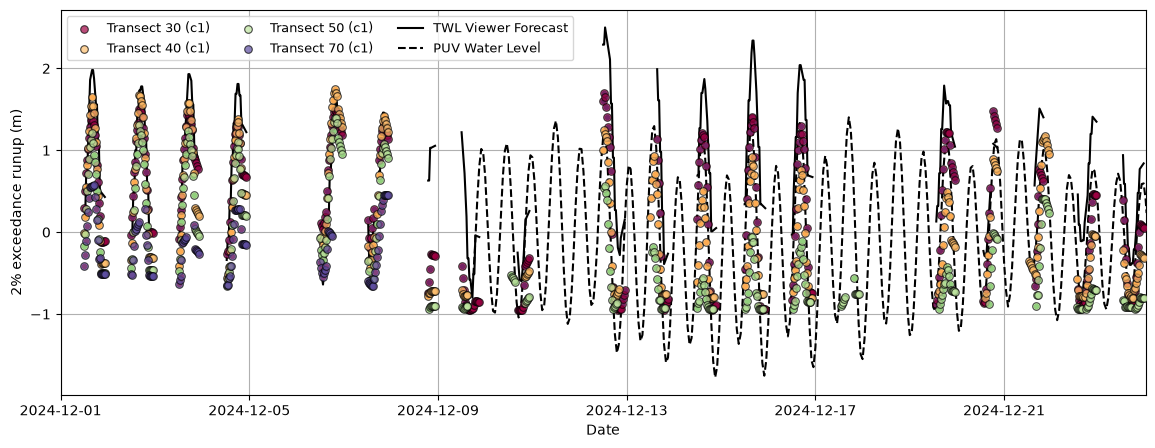

In [40]:
combined_index = pd.date_range(start=min(df_puv.index.min(),df_ss20_c1.index.min(),df_ss30_c1.index.min(),df_ss40_c1.index.min(),df_ss50_c1.index.min(),df_ss70_c1.index.min()),end=max(df_puv.index.max(),df_ss20_c1.index.max(),df_ss30_c1.index.max(),df_ss40_c1.index.max(),df_ss50_c1.index.max(),df_ss70_c1.index.max()), #df_ss50_c2.index.min(),df_ss70_c2.index.min(),df_ss100_c2.index.min(),df_ss150_c2.index.min()), df_ss50_c2.index.max(),df_ss70_c2.index.max(),df_ss100_c2.index.max(),df_ss150_c2.index.max()),
                                freq='30min')

# Step 2: Reindex both DataFrames to the combined index
# Step 3: Interpolate missing values (linear interpolation in time)
df_puv_interp = df_puv.reindex(combined_index).interpolate(method='time',limit=4)
df_ss20_c1_interp = df_ss20_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss30_c1_interp = df_ss30_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss40_c1_interp = df_ss40_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss50_c1_interp = df_ss50_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss70_c1_interp = df_ss70_c1.reindex(combined_index).interpolate(method='time',limit=4)

# df_ss50_c2_interp = df_ss50_c2.reindex(combined_index).interpolate(method='time',limit=4)
# df_ss70_c2_interp = df_ss70_c2.reindex(combined_index).interpolate(method='time',limit=4)
# df_ss100_c2_interp = df_ss100_c2.reindex(combined_index).interpolate(method='time',limit=4)     
# df_ss150_c2_interp = df_ss150_c2.reindex(combined_index).interpolate(method='time',limit=4)

print(f"Reindexed DataFrames: {len(df_puv_interp)} rows, {len(df_ss20_c1_interp)} rows")

# Optional: Combine into one DataFrame
frames = {
    # (20, "c1"): df_ss20_c1_interp,
    (30, "c1"): df_ss30_c1_interp,
    (40, "c1"): df_ss40_c1_interp,
    (50, "c1"): df_ss50_c1_interp,
    (70, "c1"): df_ss70_c1_interp,
    # (50, "c2"): df_ss50_c2_interp,
    # (70, "c2"): df_ss70_c2_interp,
    # (100, "c2"): df_ss100_c2_interp,
    # (150, "c2"): df_ss150_c2_interp,
}
aligned_df = pd.concat(frames, axis=1, names=["transect", "camera", "variable"])
ru = aligned_df.xs("ss_twl_mean", axis=1, level="variable")   # cols: (transect, camera)

cmap = plt.colormaps["Spectral"]
colors = cmap(np.linspace(0, 1, len(frames)))

fig,ax = plt.subplots(figsize=[14,5])
ax.grid(True, zorder=0)
for (t, cam), s in ru.items():
    ax.scatter(s.index, s, s=30, alpha=0.7, zorder=3,edgecolor='black',linewidth=0.8,color=colors[list(frames.keys()).index((t, cam))], label=f"Transect {t} ({cam})")
ax.set(xlabel="Date", ylabel="2% exceedance runup (m)")

plt.plot(aligned_df[(30, 'c1', 'cc_twl')],label="TWL Viewer Forecast",color='black')
plt.plot(df_puv_interp['water_level'],color='black',linestyle='--',label="PUV Water Level")
plt.plot(ru, linestyle='None',marker='.')
plt.legend(ncol=3, fontsize=9)
plt.xlim([pd.Timestamp('2024-12-01'), pd.Timestamp('2024-12-24')])
plt.savefig(f"TWL_Comparison_Shorescan_PUV_{plt.xlim()[0]}-{plt.xlim()[1]}.png", dpi=150)
plt.show()


Reindexed DataFrames: 4759 rows, 4759 rows


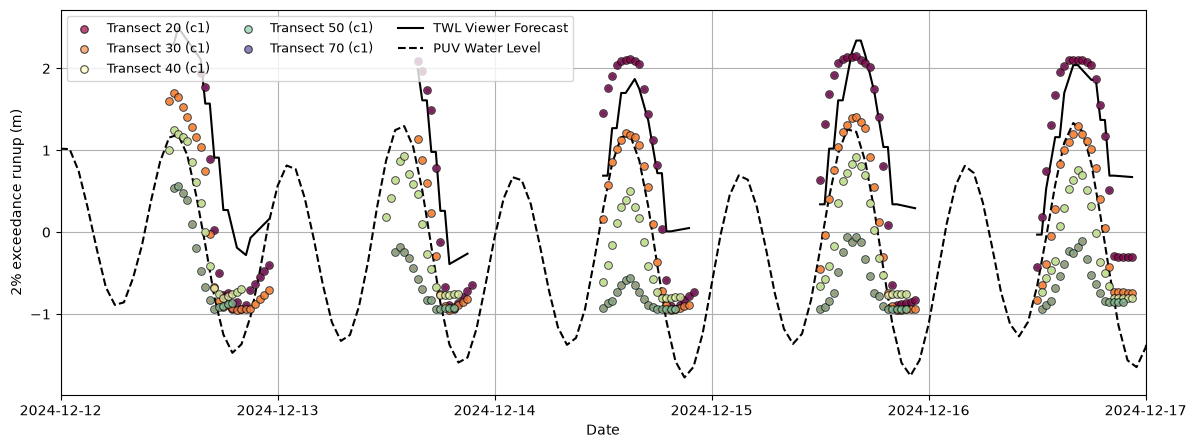

In [41]:
combined_index = pd.date_range(start=min(df_puv.index.min(),df_ss20_c1.index.min(),df_ss30_c1.index.min(),df_ss40_c1.index.min(),df_ss50_c1.index.min(),df_ss70_c1.index.min()),end=max(df_puv.index.max(),df_ss20_c1.index.max(),df_ss30_c1.index.max(),df_ss40_c1.index.max(),df_ss50_c1.index.max(),df_ss70_c1.index.max()), #df_ss50_c2.index.min(),df_ss70_c2.index.min(),df_ss100_c2.index.min(),df_ss150_c2.index.min()), df_ss50_c2.index.max(),df_ss70_c2.index.max(),df_ss100_c2.index.max(),df_ss150_c2.index.max()),
                                freq='30min')

# Step 2: Reindex both DataFrames to the combined index
# Step 3: Interpolate missing values (linear interpolation in time)
df_puv_interp = df_puv.reindex(combined_index).interpolate(method='time',limit=4)
df_ss20_c1_interp = df_ss20_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss30_c1_interp = df_ss30_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss40_c1_interp = df_ss40_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss50_c1_interp = df_ss50_c1.reindex(combined_index).interpolate(method='time',limit=4)
df_ss70_c1_interp = df_ss70_c1.reindex(combined_index).interpolate(method='time',limit=4)

# df_ss50_c2_interp = df_ss50_c2.reindex(combined_index).interpolate(method='time',limit=4)
# df_ss70_c2_interp = df_ss70_c2.reindex(combined_index).interpolate(method='time',limit=4)
# df_ss100_c2_interp = df_ss100_c2.reindex(combined_index).interpolate(method='time',limit=4)     
# df_ss150_c2_interp = df_ss150_c2.reindex(combined_index).interpolate(method='time',limit=4)

print(f"Reindexed DataFrames: {len(df_puv_interp)} rows, {len(df_ss20_c1_interp)} rows")

# Optional: Combine into one DataFrame
frames = {
    (20, "c1"): df_ss20_c1_interp,
    (30, "c1"): df_ss30_c1_interp,
    (40, "c1"): df_ss40_c1_interp,
    (50, "c1"): df_ss50_c1_interp,
    (70, "c1"): df_ss70_c1_interp,
    # (50, "c2"): df_ss50_c2_interp,
    # (70, "c2"): df_ss70_c2_interp,
    # (100, "c2"): df_ss100_c2_interp,
    # (150, "c2"): df_ss150_c2_interp,
}
aligned_df = pd.concat(frames, axis=1, names=["transect", "camera", "variable"])
ru = aligned_df.xs("ss_twl_mean", axis=1, level="variable")   # cols: (transect, camera)

cmap = plt.colormaps["Spectral"]
colors = cmap(np.linspace(0, 1, len(frames)))

fig,ax = plt.subplots(figsize=[14,5])
ax.grid(True, zorder=0)
for (t, cam), s in ru.items():
    ax.scatter(s.index, s, s=30, alpha=0.7, zorder=3,edgecolor='black',linewidth=0.8,color=colors[list(frames.keys()).index((t, cam))], label=f"Transect {t} ({cam})")
ax.set(xlabel="Date", ylabel="2% exceedance runup (m)")

plt.plot(aligned_df[(30, 'c1', 'cc_twl')],label="TWL Viewer Forecast",color='black')
plt.plot(df_puv_interp['water_level'],color='black',linestyle='--',label="PUV Water Level")
plt.plot(ru, linestyle='None',marker='.')
plt.legend(ncol=3, fontsize=9)
plt.xlim([pd.Timestamp('2024-12-12'), pd.Timestamp('2024-12-17')])
plt.savefig(f"TWL_Comparison_Shorescan_PUV_{plt.xlim()[0]}-{plt.xlim()[1]}.png", dpi=150)
plt.show()


# 3. Reverse-shoal and un-refract Sig1000 waves to deepwater

**Author:** Chelsea A. Volpano (cvolpano@gmail.com)
**Created:** 2026-11-03 · **Generated with:** Claude Opus 5.5 (claude-opus-5-5)

**Section summary (update as this section changes)**
- 2026-11-03: Added linear-wave-theory transformation of Sig1000 `Hs` from the
  sensor depth back to deep water (shoaling + Snell's-law refraction, straight and
  parallel contours). Outputs `H0_shoal` (shoaling only) and `H0` (shoaling +
  refraction), plus `L0`, `Ks`, `Kr`, `theta0`. Depth varies with tide via
  `water_depth`. Added a ±0.10 m depth-uncertainty check (VDatum/Geoid18 estimate).

**Method.** Stockdon et al. (2006) expect deepwater height $H_0$ and wavelength
$L_0 = gT_p^2/2\pi$ (https://doi.org/10.1016/j.coastaleng.2005.12.005).
Wave energy flux is conserved along a ray, so the measured height is
$H = H_0 K_s K_r$, which gives $H_0 = H / (K_s K_r)$, with

- $K_s = \sqrt{C_{g0}/C_g}$, the shoaling coefficient. $C_g = nC$, $n = \tfrac12\left(1 + \tfrac{2kh}{\sinh 2kh}\right)$, and $C_{g0} = gT/4\pi$.
- $K_r = \sqrt{\cos\theta_0/\cos\theta}$ ($\le 1$), the refraction coefficient. Snell's law gives $\sin\theta_0 = \sin\theta \, C_0/C$, where $\theta$ is the angle from shore-normal at the sensor.
- $k$ comes from Guo's (2002) explicit dispersion approximation (error < 0.1 %, https://doi.org/10.1016/S0378-3839(02)00043-1), so no iterative solver is needed.

See Dean & Dalrymple (1991), *Water Wave Mechanics for Engineers and Scientists*,
ch. 4 (https://doi.org/10.1142/1232).

**Assumptions**
- `water_depth` is the **total** still-water depth at the sensor (m) and already
  varies with tide.
- `wvdir` is the direction waves come **from**, in degrees clockwise from true north.
- The shore-normal (transect) azimuth is 80° from north, pointing offshore. A wave
  from 80° is therefore shore-normal ($\theta = 0$).
- Bathymetry contours are straight and parallel between the sensor and deep water.
  Real refraction over shoals is not captured.

### 3a. Constants and the dispersion solver

`k_guo2002` is written with NumPy array math. It accepts a whole column of periods
and depths and returns all wavenumbers in one step. That is much faster than
looping row by row or calling `scipy.optimize` for each record.

In [42]:
G = 9.81                  # gravitational acceleration (m s^-2)
SHORE_NORMAL_DEG = 80.0   # transect azimuth, deg from true north (offshore-pointing)
DEPTH_UNC_M = 0.10        # vertical uncertainty from VDatum/Geoid18 (m)
MAX_THETA0_DEG = 80.0     # mask near-grazing deepwater angles (deg)


def k_guo2002(T, h):
    '''Wavenumber k (rad/m) from Guo (2002) explicit dispersion approximation.

    T : wave period (s); h : water depth (m). Array-like; NaN propagates.
    '''
    T = np.asarray(T, dtype=float)
    h = np.asarray(h, dtype=float)
    omega = 2 * np.pi / T
    x = omega * np.sqrt(h / G)                        # = h * omega / sqrt(g h)
    kh = x**2 * (1 - np.exp(-x**2.4908))**(-1 / 2.4908)
    return kh / h

### 3b. Shoaling + refraction function

**Direction wrap-around.** Angles are made relative to shore-normal with
`(dir - normal + 180) % 360 - 180`. This maps every angle into the range
[-180°, 180°), so 350° and 10° are correctly treated as 20° apart, not 340°.

**Masking.** Two cases are set to NaN instead of producing bad values:
- Waves travelling offshore ($|\theta| \ge 90°$). There is no onshore energy flux
  to transform.
- Cases where $|\sin\theta_0| > 1$. Linear theory has no deepwater ray that could
  arrive at the sensor at that angle.
- Deepwater angles beyond `MAX_THETA0_DEG` (80°). Close to grazing incidence,
  $K_r \to 0$, so $H_0$ becomes unrealistically large and extremely sensitive to
  direction error. The straight-contour assumption is also least valid there.

`np.errstate` silences the warnings these NaNs would otherwise print.

In [43]:
def deshoal_linear(Hs, Tp, h, wave_dir, shore_normal=SHORE_NORMAL_DEG,
                   max_theta0=MAX_THETA0_DEG):
    '''Transform measured Hs at depth h back to deep water (linear theory).

    Parameters
    ----------
    Hs, Tp, h : array-like
        Significant wave height (m), peak period (s), total depth (m).
    wave_dir : array-like
        Direction waves come FROM (deg clockwise from true north).
    shore_normal : float
        Offshore-pointing shore-normal azimuth (deg from true north).
    max_theta0 : float
        Largest deepwater angle (deg) kept; near 90 deg, Kr -> 0 and H0 blows up.

    Returns
    -------
    pandas.DataFrame with k, kh, Ks, Kr, theta (at sensor), theta0 (deep),
    H0_shoal (shoaling only), H0 (shoaling + refraction), L0.
    '''
    Hs, Tp, h, wave_dir = (np.asarray(a, dtype=float)
                           for a in (Hs, Tp, h, wave_dir))
    with np.errstate(invalid='ignore', divide='ignore', over='ignore'):
        k = k_guo2002(Tp, h)
        kh = k * h
        omega = 2 * np.pi / Tp

        # Phase and group speeds at the sensor and in deep water
        C = omega / k
        n = 0.5 * (1 + 2 * kh / np.sinh(2 * kh))
        Cg = n * C
        C0 = G * Tp / (2 * np.pi)
        Cg0 = 0.5 * C0
        Ks = np.sqrt(Cg0 / Cg)

        # Angle from shore-normal, wrapped to [-180, 180)
        theta = np.deg2rad((wave_dir - shore_normal + 180) % 360 - 180)
        sin_t0 = np.sin(theta) * C0 / C
        theta0 = np.arcsin(np.clip(sin_t0, -1, 1))
        valid = ((np.abs(theta) < np.pi / 2) & (np.abs(sin_t0) <= 1)
                 & (np.abs(theta0) <= np.deg2rad(max_theta0)))
        theta0 = np.where(valid, theta0, np.nan)
        Kr = np.where(valid, np.sqrt(np.cos(theta0) / np.cos(theta)), np.nan)

        H0_shoal = Hs / Ks
        H0 = Hs / (Ks * Kr)
        L0 = G * Tp**2 / (2 * np.pi)

    return pd.DataFrame({
        'k': k, 'kh': kh, 'Ks': Ks, 'Kr': Kr,
        'theta_deg': np.rad2deg(theta), 'theta0_deg': np.rad2deg(theta0),
        'H0_shoal': H0_shoal, 'H0': H0, 'L0': L0,
    })

### 3c. Apply to the Sig1000 record

The transformation runs on `puv` at its native hourly timestamps. The results are
then joined onto `aligned_df` by time, with **no interpolation of direction**.
Linear interpolation of an angle across the 0°/360° boundary would be wrong:
for example, 350° and 10° would average to 180°.

Note that `puv.resample("1h").mean()` in Section 1 also averages directions
arithmetically. This is harmless while the Sig1000 file is already hourly
(one value per bin). If you ever resample sub-hourly data, average the direction
as a vector instead (mean of sin and cos, then `arctan2`).

In [44]:
# Fill values (>= 99) were set to NaN in load_puv_csv; also drop non-physical depths
depth = df_puv['water_depth'].where(df_puv['water_depth'] > 0)

deep = deshoal_linear(df_puv['Hs'], df_puv['Tp'], depth, df_puv['wvdir'])
deep.index = df_puv.index                             # restore timestamps (UTC)
deep[['Hs','Tp']] = df_puv[['Hs','Tp']]
puv_cols = ['Hs', 'Tp', 'H0_shoal', 'H0', 'L0', 'Ks', 'Kr', 'theta0_deg', 'kh']
for col in puv_cols:
    df_puv[col] = deep[col]
    
puv_ml = pd.concat({("puv", "-"): df_puv[puv_cols]}, axis=1,
                   names=["transect", "camera", "variable"])

# Replace (not append) the PUV block so this cell is safe to re-run
aligned_df = (aligned_df
              .drop(columns="puv", level="transect", errors="ignore")
              .join(puv_ml))

n_tot = df_puv['Hs'].notna().sum()
n_ref = df_puv['H0'].notna().sum()
print(f'kh range: {df_puv.kh.min():.2f} - {df_puv.kh.max():.2f} '
      f'(deep water if kh > pi)')
print(f'Ks range: {df_puv.Ks.min():.3f} - {df_puv.Ks.max():.3f}')
print(f'Kr range: {df_puv.Kr.min():.3f} - {df_puv.Kr.max():.3f}')
print(f'Records with valid refraction: {n_ref}/{n_tot} '
      f'({n_tot - n_ref} offshore-directed, no deepwater solution, '
      f'or theta0 > {MAX_THETA0_DEG} deg -> NaN)')
print(df_puv[['Hs', 'H0_shoal', 'H0']].describe().round(3))

kh range: 0.59 - 14.91 (deep water if kh > pi)
Ks range: 0.914 - 1.017
Kr range: 0.574 - 1.000
Records with valid refraction: 1850/2182 (332 offshore-directed, no deepwater solution, or theta0 > 80.0 deg -> NaN)
             Hs  H0_shoal        H0
count  2182.000  2182.000  1850.000
mean      1.003     1.055     1.086
std       0.534     0.572     0.628
min       0.171     0.186     0.191
25%       0.621     0.648     0.636
50%       0.901     0.945     0.944
75%       1.264     1.326     1.384
max       3.558     3.860     3.882


### 3d. Sensitivity to the ±0.10 m vertical uncertainty

This re-runs the transformation with the depth shifted by ±0.10 m. Because the
function is vectorized, each run costs only milliseconds, even for thousands of
rows. The result gives one term of your wave-input uncertainty budget.

In [45]:
H0_lo = deshoal_linear(df_puv['Hs'], df_puv['Tp'], depth - DEPTH_UNC_M, df_puv['wvdir'])['H0']
H0_hi = deshoal_linear(df_puv['Hs'], df_puv['Tp'], depth + DEPTH_UNC_M, df_puv['wvdir'])['H0']
dH0 = np.abs(H0_hi.values - H0_lo.values) / 2

print(f'H0 change from ±{DEPTH_UNC_M} m depth error: '
      f'median {np.nanmedian(dH0) * 1000:.2f} mm, '
      f'max {np.nanmax(dH0) * 1000:.2f} mm')

H0 change from ±0.1 m depth error: median 0.43 mm, max 21.22 mm


### 3e. Quick-look figure

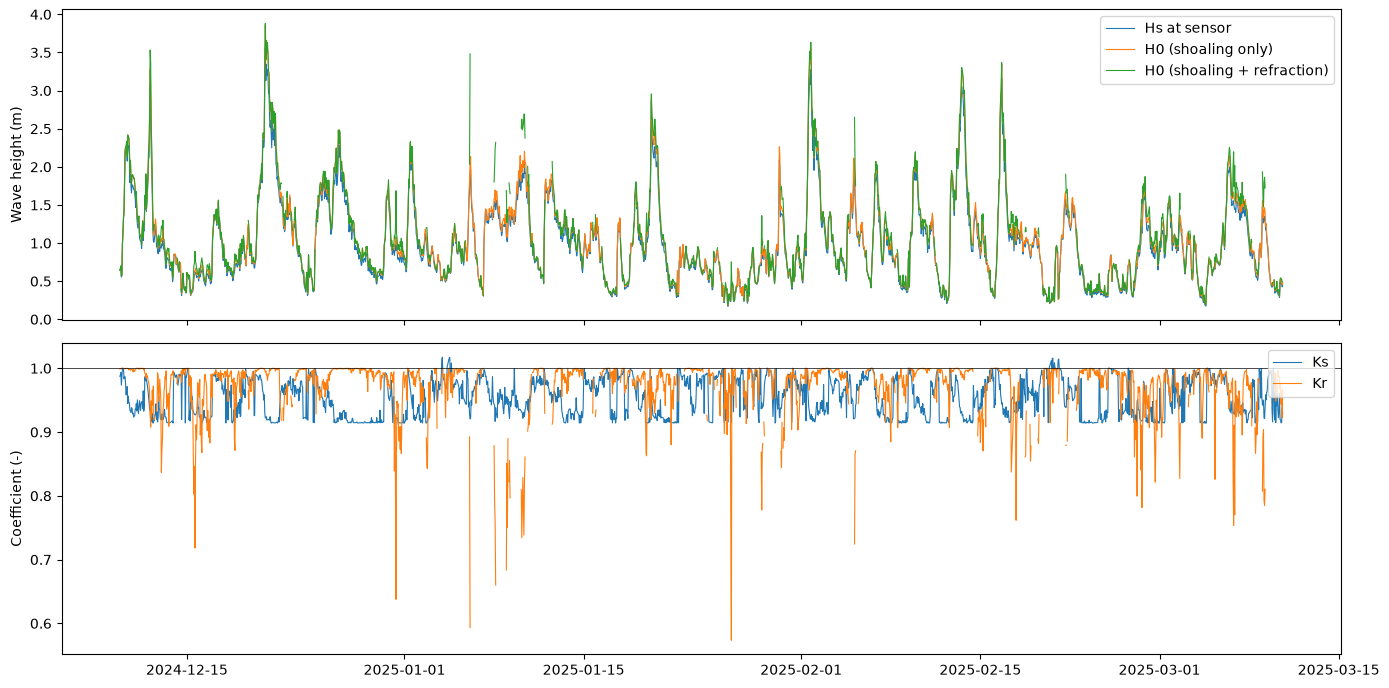

In [46]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax1.plot(df_puv.index, df_puv['Hs'], lw=0.8, label='Hs at sensor')
ax1.plot(df_puv.index, df_puv['H0_shoal'], lw=0.8, label='H0 (shoaling only)')
ax1.plot(df_puv.index, df_puv['H0'], lw=0.8, label='H0 (shoaling + refraction)')
ax1.set_ylabel('Wave height (m)')
ax1.legend(loc='upper right')

ax2.plot(df_puv.index, df_puv['Ks'], lw=0.8, label='Ks')
ax2.plot(df_puv.index, df_puv['Kr'], lw=0.8, label='Kr')
ax2.axhline(1, color='k', lw=0.5)
ax2.set_ylabel('Coefficient (-)')
ax2.legend(loc='upper right')

fig.tight_layout()
plt.show()

### 3f. Use in Stockdon (2006)

Pass the deepwater height to `py_wave_runup` in place of the sensor `Hs`.
`Stockdon2006` computes $L_0$ internally from `Tp`. For example:

```python
sto = models.Stockdon2006(Hs=aligned_df['H0'], Tp=aligned_df['Tp'], beta=beta)
aligned_df['R2_sig1000'] = sto.R2
```

To quantify how much refraction matters for your uncertainty analysis, compare
runs using `H0` and `H0_shoal`.

[(20, 'c1', 'transect'), (20, 'c1', 'ss_twl_mean'), (20, 'c1', 'ss_twl_min'), (20, 'c1', 'ss_twl_max'), (20, 'c1', 'ss_twl_std'), (20, 'c1', 'ss_twl_2pct'), (20, 'c1', 'ss_twl_2pct_peaks'), (20, 'c1', 'ss_n_peaks'), (20, 'c1', 'ss_twl_2pct_peaks_file'), (20, 'c1', 'ss_twl_2pct_file'), (20, 'c1', 'ss_S'), (20, 'c1', 'ss_S_file'), (20, 'c1', 'ss_S_ss'), (20, 'c1', 'ss_S_ig'), (20, 'c1', 'ss_Tpeak'), (20, 'c1', 'ss_Tmean'), (20, 'c1', 'ss_setup_file'), (20, 'c1', 'beta06'), (20, 'c1', 'ss_beta'), (20, 'c1', 'cc_twl'), (20, 'c1', 'cc_twl05'), (20, 'c1', 'cc_twl95'), (20, 'c1', 'cc_tide'), (20, 'c1', 'cc_setup'), (20, 'c1', 'cc_ru_2pct'), (20, 'c1', 'cc_ru05'), (20, 'c1', 'cc_ru95'), (20, 'c1', 'cc_swash'), (20, 'c1', 'cc_swash_inc'), (20, 'c1', 'cc_swash_ig'), (20, 'c1', 'cc_Hs'), (20, 'c1', 'cc_Tp'), (20, 'c1', 'cc_lead_h'), (20, 'c1', 'cc_swl'), (20, 'c1', 'ss_ref_tide'), (20, 'c1', 'mode_frac'), (20, 'c1', 'elev_min'), (20, 'c1', 'elev_max'), (20, 'c1', 'ss_R2'), (20, 'c1', 'ss_setup'),

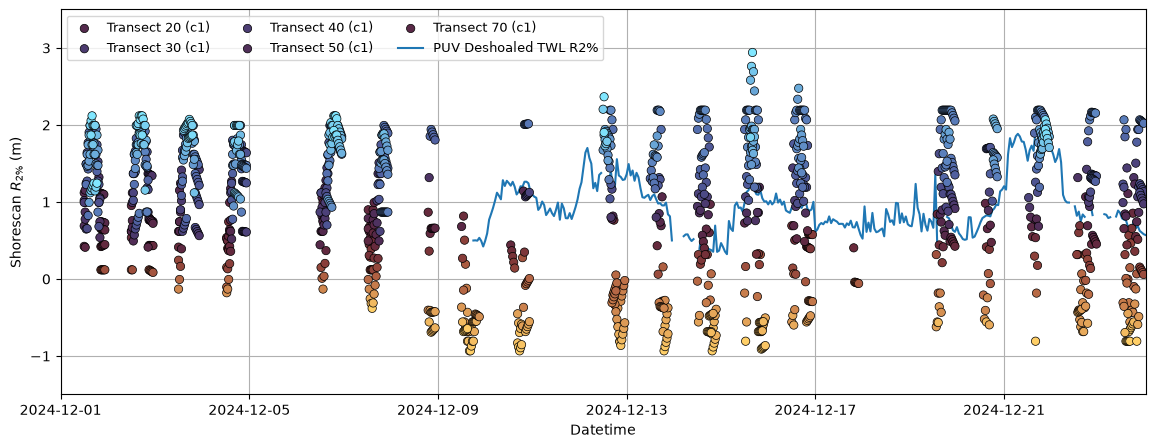

In [77]:
def get_var(df, var):
    """Return `var` from every (transect, camera) that has it; empty frame if none."""
    if var not in df.columns.get_level_values("variable"):
        return pd.DataFrame(index=df.index)        # nothing to plot, no crash
    return df.xs(var, axis=1, level="variable")    # cols: (transect, camera)
lng = len(df_puv)

keys = list(aligned_df.keys())
print(keys)
print(list(df_puv))
beta = 0.1
beta_ln = [beta]*lng

sto = models.Stockdon2006(Hs=df_puv['H0'], Tp=df_puv['Tp'], beta=beta_ln)

print((sto))
R2_sig1000 = sto.R2

r2 = get_var(aligned_df, "ss_twl_2pct_peaks")
setup = get_var(aligned_df,"ss_setup_file")
tide = get_var(aligned_df,"cc_tide")
print(tide)


fig, ax = plt.subplots(figsize=(14, 5))
ax.grid(True, zorder=0)
for (t, cam), s in r2.items():
    r2[t, cam] = s - setup[t, cam] - tide[t, cam]
    ax.scatter(s.index, s, edgecolor="k", linewidths=0.5, zorder=5,
               label=f"Transect {t} ({cam})",c=s,cmap='managua')
ax.plot(df_puv.index,R2_sig1000,label='PUV Deshoaled TWL R2%')
ax.set(xlabel="Datetime", ylabel="Shorescan $R_{2\\%}$ (m)",ylim=[-1.5,3.5],xlim=([pd.Timestamp('12-01-2024'),pd.Timestamp('12-24-2024')]))
ax.legend(ncol=3, fontsize=9)
plt.show()


In [48]:
Hs = get_var(aligned_df, "Hs")   # cols: (transect, camera)
Tp = get_var(aligned_df, "Tp")   # cols: (transect, camera)
beta06 = get_var(aligned_df, "beta06")   # cols: (transect, camera)

H0 = aligned_df[("puv", "-", "H0")]           # deshoaled deep-water height
Tp = aligned_df[("puv", "-", "Tp")]
beta = get_var(aligned_df, "beta06")          # (time, n_transects)

# Repeat the single PUV column across every transect column (no data copied yet)
H0_2d = np.broadcast_to(H0.to_numpy()[:, None], beta.shape)
Tp_2d = np.broadcast_to(Tp.to_numpy()[:, None], beta.shape)

# One vectorized model call on flattened arrays, then reshape back to (time, transect)
model_sto06 = models.Stockdon2006(Hs=H0_2d.ravel(), Tp=Tp_2d.ravel(),
                                  beta=beta.to_numpy().ravel())
R2 = pd.DataFrame(model_sto06.R2.reshape(beta.shape),
                  index=beta.index, columns=beta.columns)

# Store it back in aligned_df as a new variable for each (transect, camera)
R2.columns = pd.MultiIndex.from_tuples(
    [(t, c, "sto06_R2") for t, c in R2.columns], names=aligned_df.columns.names)
aligned_df = aligned_df.join(R2)

R2_all = get_var(aligned_df, "sto06_R2")   # cols: (transect, camera)
setup = model_sto06.setup.reshape(beta.shape)   # same pattern for setup, sinc, sig
aligned_df = (aligned_df
              .drop(columns="sto06_R2", level="variable", errors="ignore")
              .join(R2))


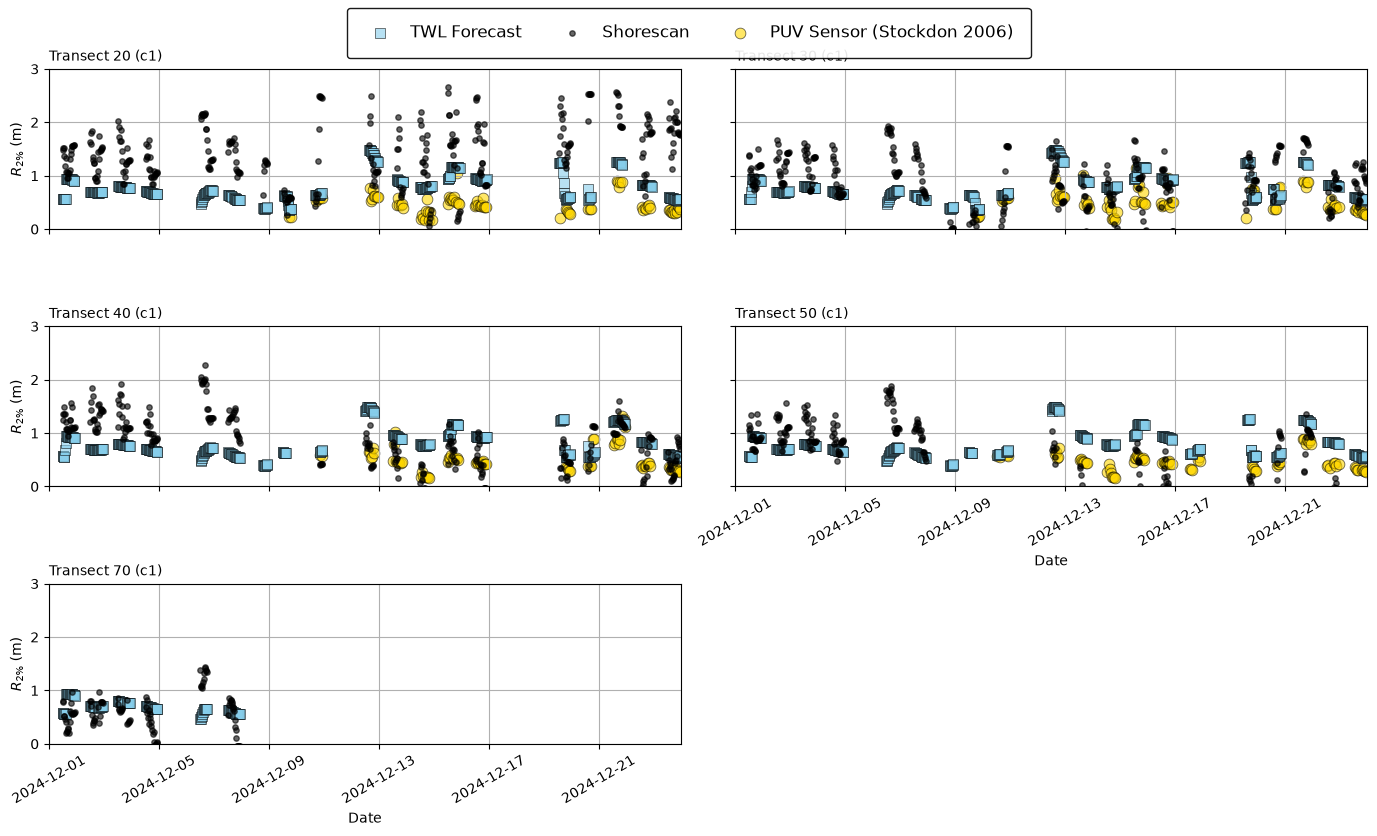

In [51]:
import math
sources = {
    "cc_ru_2pct": ("TWL Forecast", dict(marker="s", c="skyblue", edgecolor="k", linewidth=0.6, zorder=2)),
    "ss_R2": ("Shorescan", dict(marker=".", c="k", zorder=3)),
    "sto06_R2": ("PUV Sensor (Stockdon 2006)", dict(marker="o", c="gold", edgecolor="k", linewidth=0.6, zorder=1)),
}
data = {var: get_var(aligned_df, var) for var in sources}

keys = sorted(data["sto06_R2"].columns)                 # (transect, camera) pairs

ncols = 2
nrows = math.ceil(len(keys) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.8 * nrows),
                         sharex=True, sharey=True, squeeze=False)
axes_flat = axes.ravel()                     # row-major: (0,0), (0,1), (1,0), ...

for ax, key in zip(axes_flat, keys):
    ax.grid(True, zorder=0)
    for var, (label, style) in sources.items():
        if key in data[var].columns:
            ax.scatter(data[var].index, data[var][key], s=60,  alpha=0.6,
                       label=label, **style)
            ax.set_xlim(pd.to_datetime(["2024-12-01", "2024-12-24"]))
            ax.set_ylim([0, 5])
        
    ax.set_title(f"Transect {key[0]} ({key[1]})", fontsize=10, loc="left")

for ax in axes_flat[len(keys):]:             # hide the leftover panel (odd count)
    ax.set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("$R_{2\\%}$ (m)")
for ax in axes_flat[max(len(keys) - ncols, 0):len(keys)]:   # bottom panel of each column
    ax.set_xlabel("Date")
    ax.set_ylim([0,3])
    ax.tick_params(axis="x", labelrotation=30, labelbottom=True)

handles, labels = axes_flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=len(sources),
           fontsize=12, frameon=True, framealpha=0.9, edgecolor="k", borderpad=1)
fig.tight_layout(rect=(0, 0, 1, 0.96))       # leave room at top for the legend
plt.show()